Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]

Processed Data Shape:
(1000, 27)


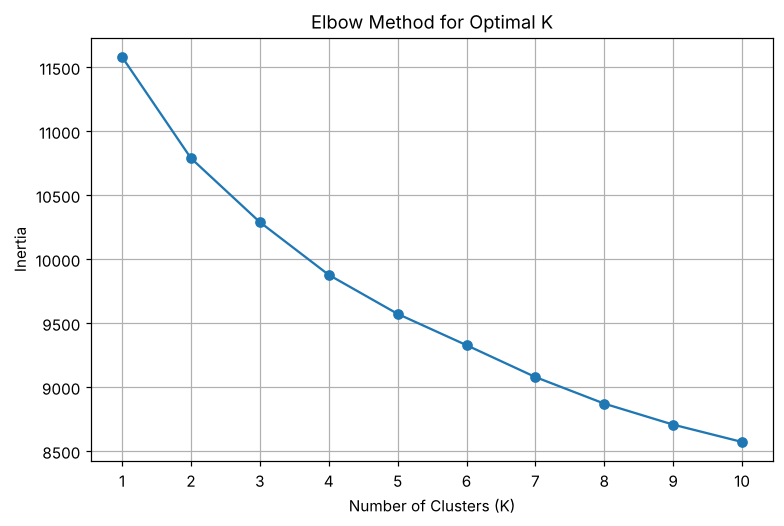


Selected Optimal K: 3

Clustered Dataset:
   Age  Gender  Cholesterol  ...   Chest Pain Type  Heart Disease Cluster
0   75  Female          228  ...   Atypical Angina              1       0
1   48    Male          204  ...    Typical Angina              0       1
2   53    Male          234  ...   Atypical Angina              1       0
3   69  Female          192  ...  Non-anginal Pain              0       1
4   62  Female          172  ...      Asymptomatic              0       0
5   77    Male          309  ...      Asymptomatic              1       0
6   64  Female          211  ...    Typical Angina              1       1
7   60  Female          208  ...      Asymptomatic              1       1
8   37  Female          317  ...  Non-anginal Pain              0       2
9   63    Male          204  ...      Asymptomatic              1       1

[10 rows x 17 columns]

Number of records in each cluster:
Cluster
0    308
1    337
2    355
Name: count, dtype: int64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)

# ------------------------------------------------------------
# Step 7: Apply Elbow Method
# ------------------------------------------------------------

inertia = []

K = range(1, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_processed)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K)

plt.grid(True)

plt.show()

# Change this value after observing the elbow plot.
optimal_k = 3

print("\nSelected Optimal K:", optimal_k)

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_processed)

df["Cluster"] = clusters

print("\nClustered Dataset:")
print(df.head(10))

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())
